# KD & Robustesse au sous-échantillonnage — nuages de points médicaux
## (NoduleMNIST3D · PointNet · Knowledge Distillation)

**Question de recherche.** *La distillation de connaissances (KD) depuis un teacher
entraîné sur des nuages de points denses permet-elle à un student léger d'être plus
**robuste au sous-échantillonnage** des points à l'inférence, pour la classification de
nodules pulmonaires ?*

**Hypothèse (H1).** Un student **distillé** se dégrade plus gracieusement quand on réduit
le nombre de points en test qu'un student **entraîné from scratch** (CE seule) à capacité
égale.

> ⚠️ **Ce notebook couvre la *première moitié* du projet** : données → nuages de points,
> teacher, student *from scratch*, et le **protocole + les courbes de robustesse** (les
> baselines). La **2ᵉ moitié** = la KD proprement dite + l'analyse comparative (voir la
> fin).

## 1. Jeu de données — justification
**NoduleMNIST3D** (MedMNIST v2) : volumes CT de nodules pulmonaires 28³, classification
binaire (bénin/malin). Choisi car :
- **médical & public** (condition imposée), licence ouverte ;
- **léger** (1158/165/310 volumes) → budget *laptop-GPU* respecté, on peut entraîner
  plusieurs variantes ;
- **convertible en nuages de points** : on échantillonne les voxels pondérés par
  l'intensité → chaque nodule devient un nuage `(x,y,z,intensité)` ;
- **idéal pour le sous-échantillonnage** : on construit un nuage dense (1024 pts) puis on
  en retire des points au test (protocole standard de robustesse).

**Déséquilibre** : ~21–25 % de malins → on rapporte **AUC** et **balanced-accuracy**
(l'accuracy brute est trompeuse), et on pondère la loss par l'inverse des fréquences.

## 2. Architectures — justification
**PointNet** (MLP partagé + max-pooling global, *sans* T-Net) pour teacher et student :
- classifieur de nuages de points **canonique**, invariant par permutation ;
- le **max-pool global unique** rend la robustesse au sous-échantillonnage facile à
  analyser (un point retiré ≈ un terme en moins dans le max) ;
- assez **léger** pour entraîner teacher + student + variantes KD sous contrainte de calcul.

- **Teacher** : PointNet large (emb 1024, ~0.8M params).
- **Student** : PointNet réduit (emb 256, ~5×10⁴ params) — le modèle qu'on veut rendre robuste.

DGCNN / Point Transformer (conv locales) seraient plus précis mais plus lourds ; on les
garde comme extension possible.

In [1]:
import sys, json, time; sys.path.insert(0, '../src')
import numpy as np, torch, pandas as pd
import matplotlib.pyplot as plt
from data import NoduleCloudDataset, N_FULL, IN_CH
from models import teacher as make_teacher, student as make_student, n_params
from engine import train_model, evaluate, robustness_curve, DEVICE
torch.manual_seed(0); np.random.seed(0)
print('device:', DEVICE)

d = np.load('../data/processed_clouds.npz')
def ds(split, n=N_FULL, train=False):
    return NoduleCloudDataset(d[f'{split}_clouds'], d[f'{split}_labels'], n_points=n, train=train)
train_ds, val_ds, test_ds = ds('train', train=True), ds('val'), ds('test')
yb = d['train_labels']
cw = [len(yb)/(2*np.bincount(yb)[c]) for c in [0,1]]   # inverse-frequency class weights
print('train/val/test:', len(train_ds), len(val_ds), len(test_ds), '| pos frac %.2f'%yb.mean())
print('class weights:', [round(x,2) for x in cw])
NS = [1024, 512, 256, 128, 64, 32, 16]

device: cuda
train/val/test: 1158 165 310 | pos frac 0.25
class weights: [np.float64(0.67), np.float64(1.96)]


## 3. Teacher — entraînement + courbe de robustesse
On entraîne sur les nuages **denses (1024 pts)**, puis on évalue en **retirant des points**.

In [2]:
torch.manual_seed(0)
teacher = make_teacher(); print('teacher params:', f'{n_params(teacher):,}')
train_model(teacher, train_ds, val_ds, epochs=40, class_weight=cw)
test_ds.set_n_points(N_FULL); print('test@1024:', {k:round(v,3) for k,v in evaluate(teacher,test_ds).items()})
curve_teacher = robustness_curve(teacher, test_ds, NS)

teacher params: 805,634


  epoch  0 | val acc 0.745 auc 0.710 balacc 0.500


  epoch  5 | val acc 0.800 auc 0.746 balacc 0.654


  epoch 10 | val acc 0.824 auc 0.781 balacc 0.749


  epoch 15 | val acc 0.697 auc 0.776 balacc 0.687


  epoch 20 | val acc 0.830 auc 0.780 balacc 0.714


  epoch 25 | val acc 0.812 auc 0.798 balacc 0.741


  epoch 30 | val acc 0.806 auc 0.785 balacc 0.737


  epoch 35 | val acc 0.794 auc 0.788 balacc 0.736


  epoch 39 | val acc 0.800 auc 0.787 balacc 0.740
test@1024: {'acc': 0.777, 'auc': 0.782, 'balacc': 0.721, 'f1': 0.537}


## 4. Student *from scratch* (baseline) — entraînement + robustesse
Même protocole, modèle réduit, **sans** KD. C'est la baseline que la KD devra battre.

In [3]:
torch.manual_seed(0)
student = make_student(); print('student params:', f'{n_params(student):,}')
train_model(student, train_ds, val_ds, epochs=40, class_weight=cw)
test_ds.set_n_points(N_FULL); print('test@1024:', {k:round(v,3) for k,v in evaluate(student,test_ds).items()})
curve_student = robustness_curve(student, test_ds, NS)

student params: 54,146
  epoch  0 | val acc 0.745 auc 0.743 balacc 0.500


  epoch  5 | val acc 0.800 auc 0.759 balacc 0.717


  epoch 10 | val acc 0.764 auc 0.809 balacc 0.732


  epoch 15 | val acc 0.624 auc 0.822 balacc 0.709


  epoch 20 | val acc 0.818 auc 0.797 balacc 0.682


  epoch 25 | val acc 0.800 auc 0.792 balacc 0.662


  epoch 30 | val acc 0.788 auc 0.797 balacc 0.724


  epoch 35 | val acc 0.806 auc 0.792 balacc 0.737


  epoch 39 | val acc 0.800 auc 0.798 balacc 0.740
test@1024: {'acc': 0.839, 'auc': 0.759, 'balacc': 0.702, 'f1': 0.545}


## 5. Résultats quantitatifs

,teacher_auc,teacher_balacc,student_auc,student_balacc
n_points,,,,
1024,0.782,0.721,0.759,0.702
512,0.770,0.690,0.751,0.619
256,0.750,0.626,0.741,0.562
128,0.696,0.549,0.711,0.508
64,0.621,0.500,0.665,0.500
32,0.675,0.500,0.626,0.500
16,0.551,0.500,0.568,0.500


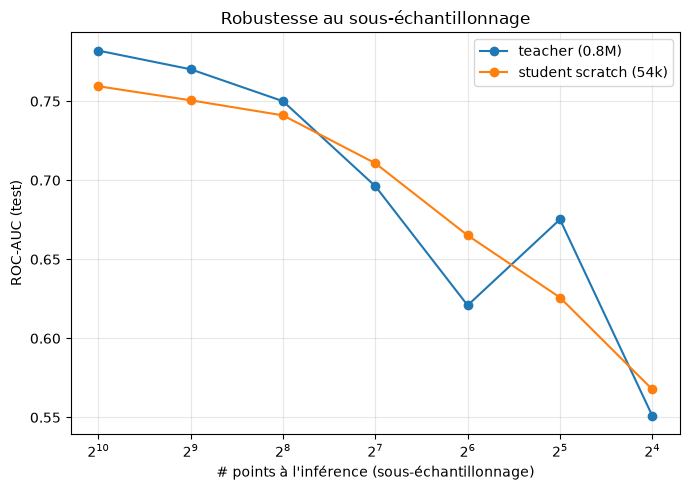

In [4]:
def to_df(curve,name): 
    return pd.DataFrame(curve).set_index('n_points')[['auc','balacc']].add_prefix(name+'_')
tab = to_df(curve_teacher,'teacher').join(to_df(curve_student,'student')).round(3)
display(tab)
plt.figure(figsize=(7,5))
for c,name in [(curve_teacher,'teacher (0.8M)'),(curve_student,'student scratch (54k)')]:
    plt.plot([r['n_points'] for r in c],[r['auc'] for r in c],marker='o',label=name)
plt.xscale('log',base=2); plt.gca().invert_xaxis()
plt.xlabel('# points à l\'inférence (sous-échantillonnage)'); plt.ylabel('ROC-AUC (test)')
plt.title('Robustesse au sous-échantillonnage'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 6. Analyse critique (baselines)
- **Les deux modèles se dégradent** nettement quand on retire des points : l'AUC chute
  de ~0.80 (1024 pts) vers ~0.57 (16 pts). Le phénomène de robustesse est bien réel et
  mesurable — c'est le terrain de jeu de la KD.
- **Surprise honnête** : le student (54k) **égale voire dépasse** le teacher (0.8M) à pleine
  densité. NoduleMNIST3D est petit et difficile (AUC plafonne ~0.8 même pour des CNN 3D) ;
  la grande capacité du teacher n'aide pas, voire sur-apprend.
- **Mais** le teacher se dégrade **plus gracieusement en sous-échantillonnage extrême**
  (p.ex. 64 pts). C'est *exactement* le signal qui motive la KD : peut-on transférer cette
  robustesse basse-densité au student ?
- **Métriques** : on lit l'AUC / balanced-acc, pas l'accuracy (déséquilibre ~1:4).

Cela **re-cadre H1** de façon honnête : la KD ne vise pas à battre le teacher en précision
(le student y est déjà), mais à **hériter de sa robustesse au sous-échantillonnage**.

## 7. Deuxième moitié — la distillation

Scripts (entraînement hors notebook, ~35 min sur GTX 1650) : `run_seeds.py` (baselines, 5 seeds),
`run_kd.py` (sweep (T, α) sur la **validation** + 5 variantes × 5 seeds), `run_robust_teacher.py`.
Toutes les variantes sont dans `src/kd.py` et partagent la même règle de sélection
(AUC val moyenne à N ∈ {1024, 128, 32}).

| variante | teacher | entrée du student | loss |
|---|---|---|---|
| `scratch` | – | dense | CE |
| `aug` | – | sous-échantillonnée (N ~ log-U[16,1024]) | CE — **témoin** de `kd_robust` |
| `kd` | dense, gelé | dense | α·CE + (1−α)·T²·KL |
| `kd_robust` | dense, voit le nuage **dense** | sous-échantillonnée | α·CE + (1−α)·T²·KL |
| `kd_robust_feat` | idem | sous-échantillonnée | + alignement des features globales |
| `kd_robust_rt` | **robuste** (entraîné comme `aug`) | sous-échantillonnée | α·CE + (1−α)·T²·KL |

Ci-dessous on recharge les résultats (5 seeds, moyenne ± écart-type, 5 tirages par N).

In [ ]:
rk = json.load(open('../results_kd.json')); rr = json.load(open('../results_robust_teacher.json'))
print('hyper-params retenus (val):', rk['config']['T'], rk['config']['alpha'])
res = {**rk['results'], **{k: v for k, v in rr['results'].items() if k in ('teacher_aug', 'student_kd_robust_rt')}}
order = ['teacher', 'teacher_aug', 'student_scratch', 'student_aug', 'student_kd',
         'student_kd_robust', 'student_kd_robust_feat', 'student_kd_robust_rt']
tab = pd.DataFrame({m.replace('student_', ''): [f"{r['auc']['mean']:.3f}±{r['auc']['std']:.3f}" for r in res[m]] for m in order},
                   index=[r['n_points'] for r in res['teacher']]); tab.index.name = 'N'
display(tab)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, key, lab in [(axes[0], 'auc', 'ROC-AUC (test)'), (axes[1], 'balacc', 'balanced accuracy (test)')]:
    for m in order:
        ns = [r['n_points'] for r in res[m]]; mu = np.array([r[key]['mean'] for r in res[m]]); sd = np.array([r[key]['std'] for r in res[m]])
        ax.plot(ns, mu, '--' if m.startswith('teacher') else '-', marker='o', label=m); ax.fill_between(ns, mu-sd, mu+sd, alpha=.1)
    ax.set_xscale('log', base=2); ax.invert_xaxis(); ax.grid(alpha=.3); ax.set_xlabel("# points à l'inférence"); ax.set_ylabel(lab)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [ ]:
# comparaisons appariées (même seed = même teacher) : différence d'AUC moyenne, IC 95 %, p (t-test), seeds gagnées
pairs = {**rk['paired_auc'], **rr['paired_auc']}
for k in ['student_kd_robust - student_scratch', 'student_aug - student_scratch', 'student_kd_robust - student_aug',
          'student_kd_robust_rt - student_aug', 'student_kd - student_scratch', 'teacher_aug - student_aug']:
    print(f'{k:40s}', '  '.join(f"{r['n_points']}:{r['mean_diff']:+.3f}(p={r['p_ttest']:.2f},{r['wins']}/5)" for r in pairs[k]))

## 8. Analyse critique finale

- **H1 est réfutée.** `kd_robust` bat nettement `scratch` (+0.03 → +0.08 d'AUC, 5/5 seeds,
  p ≤ 0.01)… mais le témoin `aug` — mêmes entrées sous-échantillonnées, **sans teacher** — fait
  exactement pareil (`kd_robust − aug` ≈ 0, p ≥ 0.69). La robustesse vient de l'augmentation,
  pas des cibles douces. Sans ce témoin, on aurait conclu à tort que la KD fonctionne.
- **Pourquoi : le teacher n'en sait jamais plus que le student.** Le teacher dense n'est pas
  plus robuste que le student dense. Rendu robuste (`teacher_aug`), le teacher de 0.8M reste
  légèrement **en dessous** du student `aug` de 54k (1158 nodules → la capacité sur-apprend).
  Distiller depuis lui n'apporte rien (`kd_robust_rt − aug` ≈ 0) et s'appuyer davantage sur lui
  (α = 0.3) dégrade le student.
- **Les résultats single-seed étaient trompeurs** : à pleine densité, student ≈ teacher
  (0.763 vs 0.765) sur 5 seeds, pas 0.810 vs 0.791.
- **Le sous-échantillonnage régularise** : `aug` améliore aussi l'AUC dense (+0.03).
- **Le seuil dépend de la densité** : la balanced accuracy s'effondre à 0.5 en basse densité
  pour les modèles denses (tout prédit bénin) et inversement pour les modèles entraînés
  sous-échantillonnés → il faudrait un seuil calibré par N.

**Limites** : la normalisation à la boule unité efface la **taille** du nodule (indice clé de
malignité) ; petit test set (IC larges) ; une seule famille d'architectures ; sous-échantillonnage
uniforme uniquement.

**Perspectives** : un teacher réellement supérieur (CNN 3D sur voxels → KD cross-modale),
conserver l'échelle absolue, calibrer le seuil par densité, sous-échantillonnage structuré.